Volume of sc is 1776.0247206315994 cm³
Volume of m06 is 1753.0296949138642 cm³
Volume of m12 is 1756.4818411102294 cm³
Volume of m24 is 1762.880440735817 cm³
Volume of m36 is 1752.9233314905166 cm³


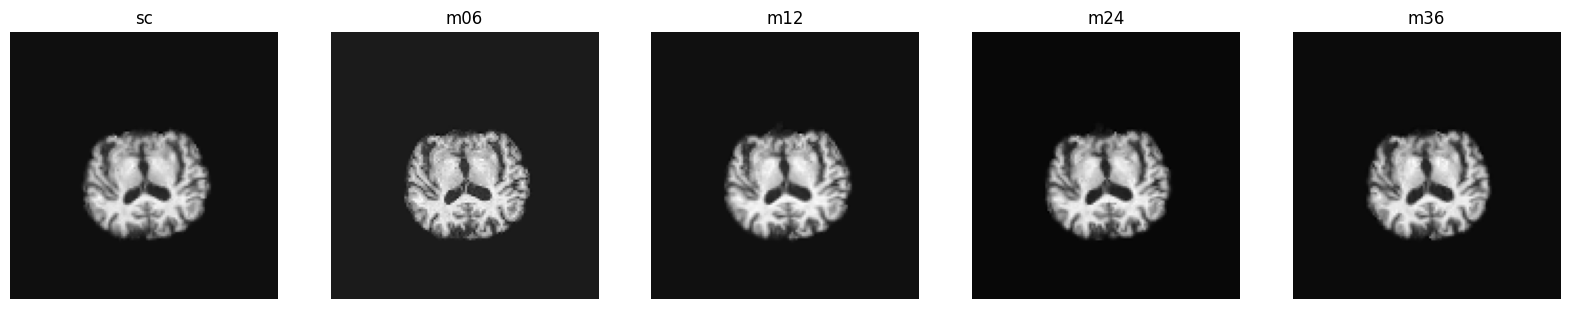

In [5]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import threshold_otsu

def calc_volume(img_path, idx, name):
    img = nib.load(img_path)
    voxel_sizes = img.header.get_zooms()  # (x, y, z) spacing in mm
    voxel_volume = np.prod(voxel_sizes)  # Compute volume of one voxel in mm³

    img = img.get_fdata()

    # normalize the image
    # img = (img - img.min()) / (img.max() - img.min())

    # Compute Otsu's threshold (ignoring zeros)
    nonzero_values = img[img > 0]
    otsu_threshold = threshold_otsu(nonzero_values) if len(nonzero_values) > 0 else 0
    adjusted_threshold = otsu_threshold * 0.85  # Reduce threshold to include more brain matter

    # Apply the threshold
    brain_mask = img != 0

    # Compute brain voxel count
    brain_voxels = np.sum(brain_mask)

    # Compute total brain volume
    brain_volume_mm3 = brain_voxels * voxel_volume  # Volume in mm³
    brain_volume_cm3 = brain_volume_mm3 / 1000  # Convert to cm³
    
    plt.subplot(1, 5, i+1)
    plt.imshow(img[:, :, brain_mask.shape[2] // 2], cmap='gray')
    plt.axis("off")
    plt.title(f"{name}")


    # return results
    return brain_volume_cm3

# Load the MRI scan
sc = "/scratch/anirudhkaushik/ADNI_Resized_Registered/ADNI_941_S_1202_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739948398_S38468_I75150_padded_transposed_padded_transposed.nii.gz"
m06 = "/scratch/anirudhkaushik/ADNI_Resized_Registered/ADNI_941_S_1202_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739948399_S25680_I63874_padded_transposed_padded_transposed.nii.gz"
m12 = "/scratch/anirudhkaushik/ADNI_Resized_Registered/ADNI_941_S_1202_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739948397_S46683_I105437_padded_transposed_padded_transposed.nii.gz"
m24 = "/scratch/anirudhkaushik/ADNI_Resized_Registered/ADNI_941_S_1202_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739948399_S63253_I137298_padded_transposed_padded_transposed.nii.gz"
m36 = "/scratch/anirudhkaushik/ADNI_Resized_Registered/ADNI_941_S_1202_MR_MPR__GradWarp__B1_Correction__N3__Scaled_Br_1739948398_S81149_I204843_padded_transposed_padded_transposed.nii.gz"

names = ["sc", "m06", "m12", "m24", "m36"]

plt.figure(figsize=(20, 5))
for i, (name, img_path) in enumerate(list(zip(names, [sc, m06, m12, m24, m36]))):
    volume = calc_volume(img_path, i, name)
    print(f"Volume of {name} is {volume} cm³")

plt.show()




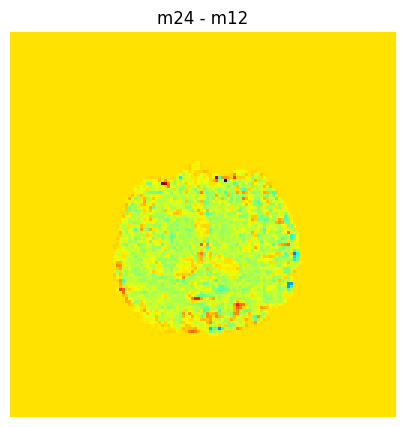

In [ ]:
# subtract m12 from m18 and plot
m06 = nib.load(m06).get_fdata()
m12 = nib.load(m12).get_fdata()
diff = m24 - m12

plt.figure(figsize=(10, 5))
plt.imshow(diff[:, :, diff.shape[2] // 2], cmap='jet')
plt.axis("off")
plt.title("m24 - m12")
plt.show()
